# Part 2: Perceptron with Regularization

Train the following three Perceptron models:

| Model | Setting |
|---|---|
| Original Perceptron | `Perceptron(penalty=None, ...)` |
| L1 Perceptron | `Perceptron(penalty='l1', ...)` |
| L2 Perceptron | `Perceptron(penalty='l2', ...)` |

Recall the Perceptron score: $z = \mathbf{w}^T\mathbf{x} + b$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)

## 1. Load the dataset

In [2]:
df = pd.read_csv("sms_spam_perceptron.csv")
print("Shape:", df.shape)
df.head()

Shape: (99, 3)


,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


## 2. Features and labels

In [3]:
LABEL_COL = "type"

feature_cols = [col for col in df.columns if col != LABEL_COL]
X = df[feature_cols]
y = df[LABEL_COL]

if y.dtype == object:
    y = y.str.strip().str.lower().map({"spam": 1, "ham": 0}).fillna(y)

print("Features:", feature_cols)
print("Label column:", LABEL_COL)
print(y.value_counts())

Features: ['sex', 'buy']
Label column: type
type
ham     75
spam    24
Name: count, dtype: int64


## 3. Train/test split

In [4]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (79, 2)  Test size: (20, 2)


## 4. Train the three Perceptron models
Only `penalty` changes; every other parameter is fixed.  

In [5]:
COMMON_PARAMS = dict(
    alpha=0.0001,      # regularization strength (sklearn default)
    max_iter=1000,
    tol=1e-3,
    eta0=1.0,
    shuffle=True,
    random_state=RANDOM_STATE,
)

model_specs = {
    "Original (None)": None,
    "L1": "l1",
    "L2": "l2",
}

models, rows = {}, []
for name, penalty in model_specs.items():
    clf = Perceptron(penalty=penalty, **COMMON_PARAMS)
    clf.fit(X_train, y_train)
    models[name] = clf

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    w = clf.coef_.ravel()

    rows.append({
        "Model": name,
        "penalty": str(penalty),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Bias (intercept_)": round(float(clf.intercept_[0]), 4),
        "||w||_1": round(np.abs(w).sum(), 4),
        "||w||_2": round(np.linalg.norm(w), 4),
        "max |w|": round(np.abs(w).max(), 4),
        "# zero weights": int(np.sum(np.isclose(w, 0))),
        "Epochs (n_iter_)": clf.n_iter_,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,penalty,Train Accuracy,Test Accuracy,Bias (intercept_),||w||_1,||w||_2,max |w|,# zero weights,Epochs (n_iter_)
Model,,,,,,,,,
Original (None),None,0.7595,0.75,-4.0,2.0000,2.0000,2.0000,1,9
L1,l1,0.7848,0.85,-3.0,1.9289,1.9289,1.9289,1,9
L2,l2,0.7848,0.85,-5.0,3.8091,3.7776,3.7774,0,9


## 5. Learned weights (`coef_`) and bias (`intercept_`)

In [6]:
for name, clf in models.items():
    print(f"===== {name} =====")
    print("coef_ (weights):\n", clf.coef_)
    print("intercept_ (bias):", clf.intercept_)
    print()

===== Original (None) =====
coef_ (weights):
 [[2. 0.]]
intercept_ (bias): [-4.]

===== L1 =====
coef_ (weights):
 [[1.9289 0.    ]]
intercept_ (bias): [-3.]

===== L2 =====
coef_ (weights):
 [[3.7774 0.0317]]
intercept_ (bias): [-5.]



### Weights side-by-side

In [7]:
weights_table = pd.DataFrame(
    {name: clf.coef_.ravel() for name, clf in models.items()},
    index=feature_cols,
)
weights_table.loc["bias (intercept_)"] = [clf.intercept_[0] for clf in models.values()]
weights_table.round(4)

,Original (None),L1,L2
sex,2.0,1.9289,3.7774
buy,0.0,0.0000,0.0317
bias (intercept_),-4.0,-3.0000,-5.0000


## 6. Visual comparison

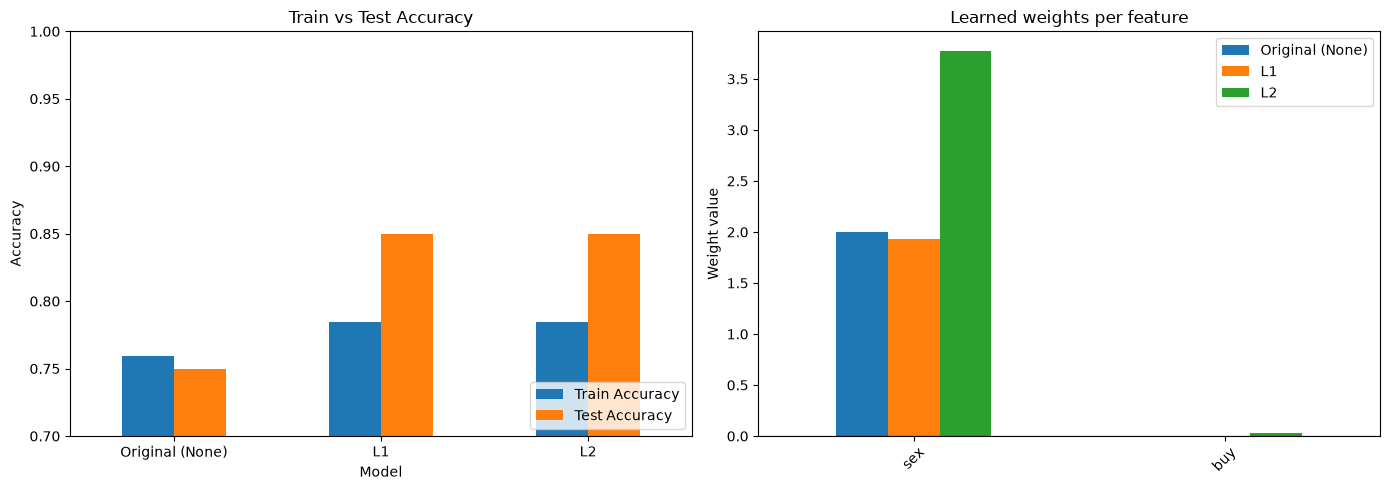

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Train vs Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(max(0, results[["Train Accuracy", "Test Accuracy"]].values.min() - 0.05), 1.0)
axes[0].legend(loc="lower right")

# Weight comparison
weights_table.drop(index="bias (intercept_)").plot(kind="bar", ax=axes[1])
axes[1].set_title("Learned weights per feature")
axes[1].set_ylabel("Weight value")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("part2_regularization.png", dpi=150)
plt.show()

## 7. Automatic summary of the differences

In [9]:
base = results.loc["Original (None)"]
for name in ["L1", "L2"]:
    r = results.loc[name]
    print(f"{name} vs Original:")
    print(f"  Test accuracy change : {r['Test Accuracy'] - base['Test Accuracy']:+.4f}")
    print(f"  Train accuracy change: {r['Train Accuracy'] - base['Train Accuracy']:+.4f}")
    print(f"  ||w||_2 ratio        : {r['||w||_2'] / base['||w||_2']:.3f}")
    print(f"  Zero weights         : {r['# zero weights']} (original: {base['# zero weights']})")
    print()

L1 vs Original:
  Test accuracy change : +0.1000
  Train accuracy change: +0.0253
  ||w||_2 ratio        : 0.964
  Zero weights         : 1 (original: 1)

L2 vs Original:
  Test accuracy change : +0.1000
  Train accuracy change: +0.0253
  ||w||_2 ratio        : 1.889
  Zero weights         : 0 (original: 1)



## 8. Analysis

**Effect on the learned weights**

- **Original Perceptron (no penalty):** 
- **L1 Perceptron:** 
- **L2 Perceptron:** 

**Effect on classification performance**

**Conclusion:** 